In [1]:

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import shap
import aif360

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)
print("AIF360:", aif360.__version__)
print("\nEnvironment ready for Responsible AI analysis!")


Python: 3.11.16
NumPy: 1.26.4
Pandas: 2.2.3
Scikit-learn: 1.5.2
SHAP: 0.49.1
AIF360: 0.6.1

Environment ready for Responsible AI analysis!


In [2]:

from aif360.datasets import AdultDataset

adult = AdultDataset(
    protected_attribute_names=["sex"],
    privileged_classes=[["Male"]],
    categorical_features=[
        "workclass",
        "education",
        "marital-status",
        "occupation",
        "relationship",
        "race",
        "native-country"
    ],
    features_to_drop=["fnlwgt"]
)

print("Dataset loaded successfully!")
print("Rows:", adult.features.shape[0])
print("Features:", adult.features.shape[1])
print("Protected attributes:", adult.protected_attribute_names)
print("Label names:", adult.label_names)
print("Protected attribute values:", adult.protected_attribute_maps)
 

IOError: [Errno 2] No such file or directory: '/Users/eepsitha/Week 1/numpy-fundamentals/week4d6-responsible-ai/.venv/lib/python3.11/site-packages/aif360/datasets/../data/raw/adult/adult.data'
To use this class, please download the following files:

	https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
	https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test
	https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.names

and place them, as-is, in the folder:

	/Users/eepsitha/Week 1/numpy-fundamentals/week4d6-responsible-ai/.venv/lib/python3.11/site-packages/aif360/data/raw/adult



SystemExit: 1

/Users/eepsitha/Week 1/numpy-fundamentals/week4d6-responsible-ai/.venv/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [3]:

from pathlib import Path
import urllib.request

data_dir = Path("data/adult")
data_dir.mkdir(parents=True, exist_ok=True)

base_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"

for filename in ["adult.data", "adult.test", "adult.names"]:
    url = base_url + filename
    destination = data_dir / filename
    print(f"Downloading {filename}...")
    urllib.request.urlretrieve(url, destination)
    print(f"Saved: {destination}")

print("\nAll three Adult Income files downloaded!")


Saved: data/adult/adult.data
Saved: data/adult/adult.test
Saved: data/adult/adult.names

All three Adult Income files downloaded!


In [4]:

from aif360.datasets import AdultDataset

adult = AdultDataset(
    protected_attribute_names=["sex"],
    privileged_classes=[["Male"]],
    categorical_features=[
        "workclass",
        "education",
        "marital-status",
        "occupation",
        "relationship",
        "race",
        "native-country"
    ],
    features_to_drop=["fnlwgt"],
    data_path="data/adult/adult.data",
    test_path="data/adult/adult.test"
)

print("Dataset loaded successfully!")
print("Rows:", adult.features.shape[0])
print("Features:", adult.features.shape[1])
print("Protected attributes:", adult.protected_attribute_names)
print("Label names:", adult.label_names)
print("Protected attribute values:", adult.protected_attribute_maps)


TypeError: AdultDataset.__init__() got an unexpected keyword argument 'data_path'

In [5]:

from pathlib import Path
import shutil
import aif360.datasets.adult_dataset as adult_module

# Locate AIF360's expected data directory
package_dir = Path(adult_module.__file__).resolve().parent.parent
target_dir = package_dir / "data" / "raw" / "adult"
target_dir.mkdir(parents=True, exist_ok=True)

# Copy the downloaded files into that directory
source_dir = Path("data/adult")

for filename in ["adult.data", "adult.test", "adult.names"]:
    source = source_dir / filename
    if not source.exists():
        raise FileNotFoundError(
            f"Cannot find {source}. Check that the download cell succeeded."
        )
    shutil.copy2(source, target_dir / filename)
    print(f"Copied {filename}")

print("AIF360 dataset files are ready!")


Copied adult.data
Copied adult.test
Copied adult.names
AIF360 dataset files are ready!


In [6]:

from aif360.datasets import AdultDataset

adult = AdultDataset(
    protected_attribute_names=["sex"],
    privileged_classes=[["Male"]],
    categorical_features=[
        "workclass",
        "education",
        "marital-status",
        "occupation",
        "relationship",
        "race",
        "native-country"
    ],
    features_to_drop=["fnlwgt"]
)

print("Dataset loaded successfully!")
print("Rows:", adult.features.shape[0])
print("Features:", adult.features.shape[1])
print("Protected attributes:", adult.protected_attribute_names)
print("Label names:", adult.label_names)
print("Protected attribute values:", adult.protected_attribute_maps)


Dataset loaded successfully!
Rows: 45222
Features: 102
Protected attributes: ['sex']
Label names: ['income-per-year']


AttributeError: 'AdultDataset' object has no attribute 'protected_attribute_maps'

In [7]:

import numpy as np

sex_index = adult.protected_attribute_names.index("sex")
sex_values = adult.protected_attributes[:, sex_index]

print("Protected attribute names:", adult.protected_attribute_names)
print("Protected attribute metadata:", adult.metadata.get("protected_attribute_maps"))
print("Encoded gender values and counts:")

values, counts = np.unique(sex_values, return_counts=True)
for value, count in zip(values, counts):
    print(f"{value}: {count}")

print("\nLabel values and counts:")
labels, label_counts = np.unique(adult.labels.ravel(), return_counts=True)
for value, count in zip(labels, label_counts):
    print(f"{value}: {count}")


Protected attribute names: ['sex']
Protected attribute metadata: [{1.0: 'White', 0.0: 'Non-white'}, {1.0: 'Male', 0.0: 'Female'}]
Encoded gender values and counts:
0.0: 14695
1.0: 30527

Label values and counts:
0.0: 34014
1.0: 11208


In [8]:

from aif360.metrics import BinaryLabelDatasetMetric

# Male is the privileged group; Female is the unprivileged group
metric = BinaryLabelDatasetMetric(
    adult,
    unprivileged_groups=[{"sex": 0.0}],
    privileged_groups=[{"sex": 1.0}]
)

print("BASELINE FAIRNESS AUDIT")
print("-" * 40)
print(f"Statistical parity difference: {metric.statistical_parity_difference():.4f}")
print(f"Disparate impact: {metric.disparate_impact():.4f}")
print(f"Mean outcome — women: {metric.mean unprivileged label:.4f}")


SyntaxError: f-string: invalid syntax. Perhaps you forgot a comma? (245478136.py, line 14)

In [9]:

from aif360.metrics import BinaryLabelDatasetMetric

metric = BinaryLabelDatasetMetric(
    adult,
    unprivileged_groups=[{"sex": 0.0}],
    privileged_groups=[{"sex": 1.0}]
)

print("BASELINE FAIRNESS AUDIT")
print("-" * 40)
print(f"Statistical parity difference: {metric.statistical_parity_difference():.4f}")
print(f"Disparate impact: {metric.disparate_impact():.4f}")
print(f"Women favorable outcome rate: {metric.base_rate(privileged=False):.4f}")
print(f"Men favorable outcome rate: {metric.base_rate(privileged=True):.4f}")


pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'


BASELINE FAIRNESS AUDIT
----------------------------------------
Statistical parity difference: -0.1989
Disparate impact: 0.3635
Women favorable outcome rate: 0.1136
Men favorable outcome rate: 0.3125


In [10]:

from aif360.algorithms.preprocessing import Reweighing

# Split the dataset into training and test sets
from sklearn.model_selection import train_test_split

train_indices, test_indices = train_test_split(
    range(len(adult.labels)),
    test_size=0.2,
    random_state=42,
    stratify=adult.labels.ravel()
)

adult_train = adult.subset(train_indices)
adult_test = adult.subset(test_indices)

# Apply reweighing to training data only
reweigher = Reweighing(
    unprivileged_groups=[{"sex": 0.0}],
    privileged_groups=[{"sex": 1.0}]
)

adult_train_reweighed = reweigher.fit_transform(adult_train)

print("Reweighing completed!")
print("Training rows:", len(adult_train.labels))
print("Test rows:", len(adult_test.labels))
print("Original training weights:", adult_train.instance_weights[:5])
print("Reweighed training weights:", adult_train_reweighed.instance_weights[:5])


Reweighing completed!
Training rows: 36177
Test rows: 9045
Original training weights: [1. 1. 1. 1. 1.]
Reweighed training weights: [1.09634269 0.84597683 0.84597683 1.09634269 0.84597683]


In [11]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import ClassificationMetric

# Convert AIF360 datasets into arrays
X_train = adult_train.features
y_train = adult_train.labels.ravel().astype(int)

X_test = adult_test.features
y_test = adult_test.labels.ravel().astype(int)

# Train baseline model
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
baseline_model.fit(X_train, y_train)

# Train mitigated model using AIF360 reweighing weights
mitigated_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
mitigated_model.fit(
    X_train,
    y_train,
    logisticregression__sample_weight=adult_train_reweighed.instance_weights
)

# Convert predictions into AIF360-compatible datasets
def make_predicted_dataset(model, test_dataset):
    predicted = test_dataset.copy(deepcopy=True)
    predicted.labels = model.predict(test_dataset.features).reshape(-1, 1)
    return predicted

baseline_pred = make_predicted_dataset(baseline_model, adult_test)
mitigated_pred = make_predicted_dataset(mitigated_model, adult_test)

privileged = [{"sex": 1.0}]
unprivileged = [{"sex": 0.0}]

baseline_metrics = ClassificationMetric(
    adult_test, baseline_pred,
    unprivileged_groups=unprivileged,
    privileged_groups=privileged
)

mitigated_metrics = ClassificationMetric(
    adult_test, mitigated_pred,
    unprivileged_groups=unprivileged,
    privileged_groups=privileged
)

results = pd.DataFrame({
    "Metric": ["Disparate Impact", "Statistical Parity Difference"],
    "Baseline": [
        baseline_metrics.disparate_impact(),
        baseline_metrics.statistical_parity_difference()
    ],
    "After Reweighing": [
        mitigated_metrics.disparate_impact(),
        mitigated_metrics.statistical_parity_difference()
    ]
})

print(results.round(4).to_string(index=False))


                       Metric  Baseline  After Reweighing
             Disparate Impact    0.2994            0.6262
Statistical Parity Difference   -0.1828           -0.0794


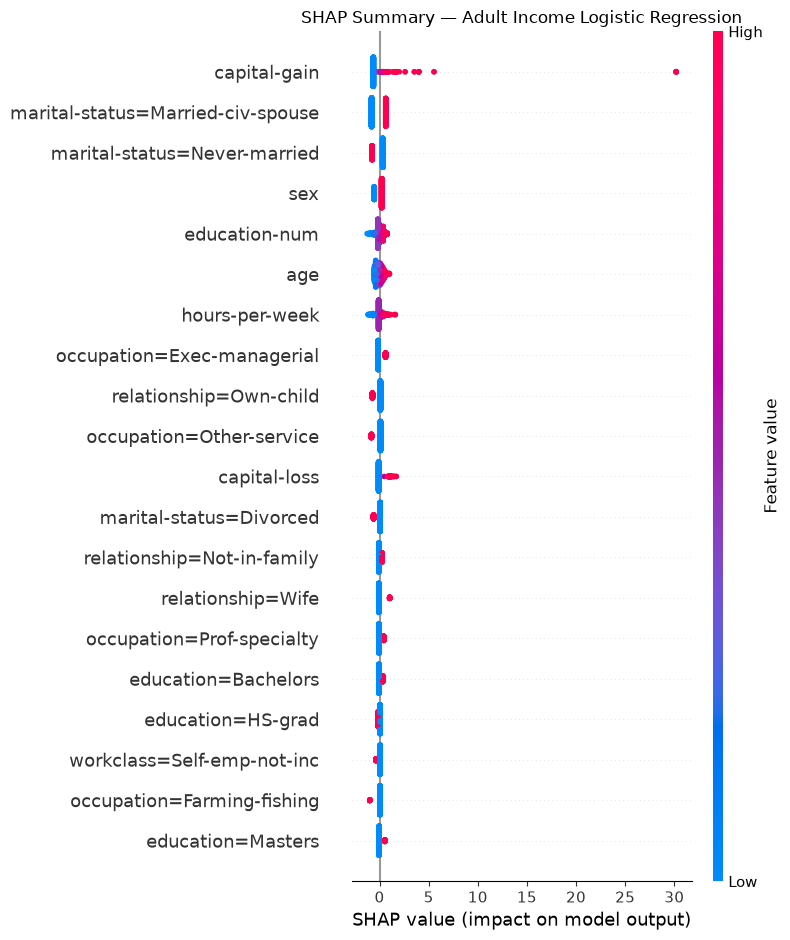

Saved SHAP summary plot to shap_summary.png


In [12]:

import shap
import matplotlib.pyplot as plt

# Scale the data using the already-trained baseline model
scaler = baseline_model.named_steps["standardscaler"]
logistic = baseline_model.named_steps["logisticregression"]

X_background = scaler.transform(X_train[:1000])
X_explain = scaler.transform(X_test[:1000])

# Explain the Logistic Regression model
explainer = shap.LinearExplainer(logistic, X_background)
shap_values = explainer(X_explain)

# Display the top 20 features
shap.summary_plot(
    shap_values.values,
    X_explain,
    feature_names=adult.feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Summary — Adult Income Logistic Regression")
plt.tight_layout()
plt.savefig(
    "shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Saved SHAP summary plot to shap_summary.png")


In [13]:

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)

output_path = "week4_model_card.pdf"

doc = SimpleDocTemplate(
    output_path,
    pagesize=A4,
    rightMargin=1.6 * cm,
    leftMargin=1.6 * cm,
    topMargin=1.3 * cm,
    bottomMargin=1.3 * cm
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="CardTitle",
    parent=styles["Title"],
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    fontSize=19,
    leading=23,
    spaceAfter=5
))
styles.add(ParagraphStyle(
    name="SmallText",
    parent=styles["BodyText"],
    fontSize=8.5,
    leading=11
))
styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    fontSize=11,
    leading=13,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=5,
    spaceAfter=3
))

story = [
    Paragraph("MODEL CARD", styles["CardTitle"]),
    Paragraph(
        "Week 4 Day 1 — Breast Cancer Classification",
        styles["Normal"]
    ),
    Spacer(1, 5),
    Paragraph("1. Model Overview", styles["SectionHeading"]),
    Paragraph(
        "A Random Forest classifier trained to classify breast cancer "
        "records using the scikit-learn breast cancer dataset. "
        "This model was developed for educational model-evaluation "
        "practice and is not approved for clinical use.",
        styles["SmallText"]
    ),
    Paragraph("2. Intended Use", styles["SectionHeading"]),
    Paragraph(
        "Educational experimentation with classification metrics, "
        "cross-validation and model evaluation. It must not be used "
        "to diagnose, screen, or make treatment decisions for patients.",
        styles["SmallText"]
    ),
    Paragraph("3. Dataset", styles["SectionHeading"]),
    Paragraph(
        "Dataset: scikit-learn Breast Cancer Wisconsin dataset. "
        "569 records and 30 numeric features. Evaluation used a "
        "held-out test set and 5-fold stratified cross-validation.",
        styles["SmallText"]
    ),
    Paragraph("4. Performance", styles["SectionHeading"])
]

metrics_data = [
    ["Metric", "Held-out test result"],
    ["Accuracy", "0.9561"],
    ["Precision", "0.9589"],
    ["Recall", "0.9722"],
    ["F1 score", "0.9655"],
    ["ROC-AUC", "0.9937"],
    ["5-fold CV ROC-AUC (mean ± SD)", "0.9885 ± 0.0083"]
]

table = Table(metrics_data, colWidths=[8.3 * cm, 7.0 * cm])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 8.5),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#B8C4D1")),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1),
     [colors.white, colors.HexColor("#EEF3F8")]),
    ("TOPPADDING", (0, 0), (-1, -1), 4),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
]))

story.extend([
    table,
    Paragraph("5. Limitations and Risks", styles["SectionHeading"]),
    Paragraph(
        "Performance metrics alone do not establish clinical safety, "
        "generalizability, calibration, or fairness across demographic "
        "groups. Dataset representativeness and subgroup performance "
        "require further investigation. Predictions must not replace "
        "professional medical assessment.",
        styles["SmallText"]
    ),
    Paragraph("6. Responsible Use", styles["SectionHeading"]),
    Paragraph(
        "Use only for learning and reproducible evaluation. Before any "
        "real-world deployment, conduct independent validation, subgroup "
        "fairness analysis, calibration checks, privacy review, and "
        "domain-expert assessment.",
        styles["SmallText"]
    ),
    Spacer(1, 5),
    Paragraph(
        "Version: 1.0 | Prepared: 10 October 2026 | "
        "Purpose: Educational documentation",
        styles["SmallText"]
    )
])

doc.build(story)
print(f"Created: {output_path}")


Created: week4_model_card.pdf
